In [4]:
# cell1 实验配置与环境记录

import hashlib
import importlib.util
import json
import math
import pickle
import platform
import random
import statistics
import sys
import time
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display


ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "workspaces" / "A3_性能").is_dir()),
    None,
)
if ROOT is None:
    raise RuntimeError("无法从当前目录向上定位 route_plan 仓库根目录。")
A3_ROOT = ROOT / "workspaces" / "A3_性能"
METHOD_DIR = A3_ROOT / "01_基准方法"
CODE_DIR = METHOD_DIR / "代码"
NOTEBOOK_DIR = METHOD_DIR / "notebooks"

DATA_DIR = (
    A3_ROOT / "武汉路网数据"
    / "03_处理结果" / "2026-10-16_武汉路网复核"
)
GRAPH_FILE = DATA_DIR / "graph_v2.pkl"
QUERY_FILE = DATA_DIR / "stratified_queries_100.json"

BASELINE_FILE = ROOT / "workspaces" / "A2_算法" / "01_实现清单" / "dijkstra.py"
VARIANTS_FILE = CODE_DIR / "dijkstra_variants.py"
RESULT_ROOT = A3_ROOT / "03_实验结果" / "武汉" / "Dijkstra"
RESULT_DIR = RESULT_ROOT / datetime.now().strftime("run_%Y%m%d_%H%M%S_%f")

BASELINE_COMMIT = "eb3597934a548563f36078703df951ddae6aa6d6"
EXPECTED_GRAPH_POLICY = "wuhan-static-public-way-distance-v2.1"

ROUNDS = 5
WARMUP_QUERY_COUNT = 5
ORDER_SEED = 20261016
ABS_TOL_M = 1e-5

ENVIRONMENT = {
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "executable": sys.executable,
    "recorded_at": datetime.now().astimezone().isoformat(timespec="seconds"),
    "baseline_commit": BASELINE_COMMIT,
    "baseline_file": str(BASELINE_FILE),
    "baseline_sha256": hashlib.sha256(BASELINE_FILE.read_bytes()).hexdigest(),
}

print(f"Notebook directory: {NOTEBOOK_DIR}")
print(f"Graph: {GRAPH_FILE}")
print(f"Queries: {QUERY_FILE}")
print(f"Python: {ENVIRONMENT['python']}")
print(f"Rounds: {ROUNDS}; warm-up queries per version: {WARMUP_QUERY_COUNT}")

Notebook directory: d:\pycharm\projects\route_plan\workspaces\A3_性能\01_基准方法\notebooks
Graph: d:\pycharm\projects\route_plan\workspaces\A3_性能\武汉路网数据\03_处理结果\2026-10-16_武汉路网复核\graph_v2.pkl
Queries: d:\pycharm\projects\route_plan\workspaces\A3_性能\武汉路网数据\03_处理结果\2026-10-16_武汉路网复核\stratified_queries_100.json
Python: 3.11.17
Rounds: 5; warm-up queries per version: 5


In [5]:
# Cell 2：加载、核验路网并准备算法输入
# 仅加载本项目生成的可信 pickle 文件；不要对不可信来源使用 pickle.load。


t0 = time.perf_counter_ns()
with GRAPH_FILE.open("rb") as f:
    graph_data = pickle.load(f)
graph_load_ms = (time.perf_counter_ns() - t0) / 1e6

N_NODES = int(graph_data["n_nodes"])
indptr = graph_data["indptr"]
indices = graph_data["indices"]
weights = graph_data["weights"]
edge_ids = graph_data["edge_ids"]
edge_records = graph_data["edges"]
N_EDGES = len(edge_records)

if len(indptr) != N_NODES + 1 or int(indptr[0]) != 0 or int(indptr[-1]) != N_EDGES:
    raise ValueError("CSR indptr 与节点数或边数不一致")
if not (len(indices) == len(weights) == len(edge_ids) == N_EDGES):
    raise ValueError("CSR indices、weights、edge_ids 长度不一致")
if any(int(indptr[i]) > int(indptr[i + 1]) for i in range(N_NODES)):
    raise ValueError("CSR indptr 必须单调不减")

t0 = time.perf_counter_ns()
graph_triples = {
    u: [
        (int(indices[i]), float(weights[i]), int(edge_ids[i]))
        for i in range(int(indptr[u]), int(indptr[u + 1]))
    ]
    for u in range(N_NODES)
}
adjacency_conversion_ms = (time.perf_counter_ns() - t0) / 1e6

# L1 的一次性全图预检：后续查询函数可以省去重复的逐边检查。
t0 = time.perf_counter_ns()
seen_edge_ids = bytearray(N_EDGES)

for u, outgoing in graph_triples.items():
    for v, weight, eid in outgoing:
        if v not in graph_triples:
            raise ValueError(f"边 {u}->{v} 指向不存在的节点")
        if not math.isfinite(weight) or weight < 0:
            raise ValueError(f"边 {u}->{v} 的权重不是有限非负数")
        if not 0 <= eid < N_EDGES or seen_edge_ids[eid]:
            raise ValueError(f"edge_id 越界或重复：{eid}")

        seen_edge_ids[eid] = 1
        edge = edge_records[eid]
        if int(edge[0]) != u or int(edge[1]) != v:
            raise ValueError(f"edge_id={eid} 与 CSR 的边方向不一致")
        if not math.isclose(float(edge[2]), weight, rel_tol=1e-12, abs_tol=1e-9):
            raise ValueError(f"edge_id={eid} 的权重与边表不一致")

if not all(seen_edge_ids):
    raise ValueError("边表中存在未出现在 CSR 中的 edge_id")

l1_precheck_ms = (time.perf_counter_ns() - t0) / 1e6

# B1 的反向邻接表保留原始 edge_id，以便重建原图方向的路径。
t0 = time.perf_counter_ns()
reverse_graph = {u: [] for u in range(N_NODES)}
for u, outgoing in graph_triples.items():
    for v, weight, eid in outgoing:
        reverse_graph[v].append((u, weight, eid))
reverse_graph_build_ms = (time.perf_counter_ns() - t0) / 1e6

CSR_GRAPH = {
    "n_nodes": N_NODES,
    "indptr": indptr,
    "indices": indices,
    "weights": weights,
    "edge_ids": edge_ids,
    "edges": edge_records,
}

GRAPH_SHA256 = hashlib.sha256(GRAPH_FILE.read_bytes()).hexdigest()

print(f"Nodes / directed edges: {N_NODES:,} / {N_EDGES:,}")
print(f"Graph SHA-256: {GRAPH_SHA256}")
print(f"Load: {graph_load_ms:.2f} ms")
print(f"CSR → triple adjacency: {adjacency_conversion_ms:.2f} ms")
print(f"L1 whole-graph precheck: {l1_precheck_ms:.2f} ms")
print(f"B1 reverse graph build: {reverse_graph_build_ms:.2f} ms")

Nodes / directed edges: 91,638 / 207,165
Graph SHA-256: fe7492eaadb4c0d058f8d00c78aa79ee9d6597ac23d4b3280b9c0d09faaf73fa
Load: 100.38 ms
CSR → triple adjacency: 311.97 ms
L1 whole-graph precheck: 268.38 ms
B1 reverse graph build: 167.24 ms


In [6]:
# Cell 3：加载固定查询集和算法版本


def load_module(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module


baseline = load_module("a2_dijkstra_l0", BASELINE_FILE)
variants = load_module("dijkstra_variants", VARIANTS_FILE)

with QUERY_FILE.open("r", encoding="utf-8") as f:
    query_data = json.load(f)

if query_data["graph_policy"] != EXPECTED_GRAPH_POLICY:
    raise ValueError(f"查询集对应的路网版本不符：{query_data['graph_policy']}")

queries = [
    (int(q["source"]), int(q["target"]))
    for q in query_data["queries"]
]
QUERY_SHA256 = hashlib.sha256(QUERY_FILE.read_bytes()).hexdigest()

if len(queries) != 100:
    raise ValueError(f"固定查询集应为 100 组，实际为 {len(queries)} 组")
if any(s == t or not (0 <= s < N_NODES and 0 <= t < N_NODES) for s, t in queries):
    raise ValueError("查询集中存在相同起终点或越界节点")

ALGORITHM_ORDER = ("L0", "L1", "L2", "L3", "L4", "B1")

ALGORITHM_FUNCTIONS = {
    "L0": lambda graph, s, t: baseline.dijkstra(graph, s, t),
    "L1": lambda graph, s, t: variants.dijkstra_l1(graph, s, t),
    "L2": lambda graph, s, t: variants.dijkstra_l2(graph, s, t),
    "L3": lambda graph, s, t: variants.dijkstra_l3(graph, s, t),
    "L4": lambda graph, s, t: variants.dijkstra_l4(graph, s, t),
    "B1": lambda graphs, s, t: variants.dijkstra_b1(graphs[0], graphs[1], s, t),
}

ALGORITHM_INPUTS = {
    "L0": graph_triples,
    "L1": graph_triples,
    "L2": graph_triples,
    "L3": graph_triples,
    "L4": CSR_GRAPH,
    "B1": (graph_triples, reverse_graph),
}


def run_algorithm(layer, source, target, inputs=None):
    algorithm_input = ALGORITHM_INPUTS[layer] if inputs is None else inputs
    return ALGORITHM_FUNCTIONS[layer](algorithm_input, source, target)


print(f"Fixed queries: {len(queries)}")
print(f"Query-set SHA-256: {QUERY_SHA256}")
print("Versions:", ", ".join(ALGORITHM_ORDER))

Fixed queries: 100
Query-set SHA-256: aa5c728689ec18f6ef0c20e8e11fdbc8fb17063cb871abd551021bb86ba6950c
Versions: L0, L1, L2, L3, L4, B1


In [7]:
# Cell 4：边界测试与全量正确性门槛


def valid_route(result, source, target, edges):
    nodes, path_edge_ids, distance, _settled = result

    if not nodes:
        return not path_edge_ids and math.isinf(float(distance))

    if nodes[0] != source or nodes[-1] != target:
        return False
    if len(nodes) != len(path_edge_ids) + 1:
        return False

    path_weights = []
    for u, v, eid in zip(nodes, nodes[1:], path_edge_ids):
        if not 0 <= int(eid) < len(edges):
            return False

        edge = edges[int(eid)]
        if int(edge[0]) != u or int(edge[1]) != v:
            return False
        path_weights.append(float(edge[2]))

    return math.isclose(
        math.fsum(path_weights),
        float(distance),
        rel_tol=1e-10,
        abs_tol=ABS_TOL_M,
    )


# 同一组小图测试：起点等于终点，以及不可达目标。
tiny_graph = {
    0: [(1, 1.0, 0)],
    1: [],
    2: [],
}
tiny_reverse_graph = {
    0: [],
    1: [(0, 1.0, 0)],
    2: [],
}
tiny_csr = {
    "n_nodes": 3,
    "indptr": [0, 1, 1, 1],
    "indices": [1],
    "weights": [1.0],
    "edge_ids": [0],
    "edges": [(0, 1, 1.0)],
}
tiny_inputs = {
    "L0": tiny_graph,
    "L1": tiny_graph,
    "L2": tiny_graph,
    "L3": tiny_graph,
    "L4": tiny_csr,
    "B1": (tiny_graph, tiny_reverse_graph),
}

for layer in ALGORITHM_ORDER:
    same_node = run_algorithm(layer, 0, 0, tiny_inputs[layer])
    assert same_node[0] == [0] and same_node[1] == []
    assert same_node[2] == 0.0

    unreachable = run_algorithm(layer, 0, 2, tiny_inputs[layer])
    assert unreachable[0] == [] and unreachable[1] == []
    assert math.isinf(float(unreachable[2]))

correctness_records = []

for query_id, (source, target) in enumerate(queries):
    reference = run_algorithm("L0", source, target)
    reference_distance = float(reference[2])

    for layer in ALGORITHM_ORDER:
        result = reference if layer == "L0" else run_algorithm(layer, source, target)
        distance = float(result[2])

        if math.isfinite(reference_distance):
            same_distance = math.isclose(
                distance, reference_distance,
                rel_tol=1e-10, abs_tol=ABS_TOL_M,
            )
        else:
            same_distance = math.isinf(distance)

        path_is_valid = valid_route(result, source, target, edge_records)
        if not same_distance or not path_is_valid:
            raise AssertionError(
                f"{layer} 正确性失败：query={query_id}, {source}->{target}, "
                f"reference={reference_distance}, result={distance}, "
                f"path_valid={path_is_valid}"
            )

        correctness_records.append({
            "layer": layer,
            "query_id": query_id,
            "distance_m": distance,
            "settled_nodes": int(result[3]),
            "path_valid": path_is_valid,
        })

correctness_df = pd.DataFrame(correctness_records)
print(f"正确性通过：{len(queries)} 组查询 × {len(ALGORITHM_ORDER)} 个版本")
display(correctness_df.groupby("layer", sort=False).agg(
    queries=("query_id", "count"),
    mean_settled_nodes=("settled_nodes", "mean"),
))

正确性通过：100 组查询 × 6 个版本


,queries,mean_settled_nodes
layer,,
L0,100,28055.53
L1,100,28055.53
L2,100,28055.53
L3,100,28055.53
L4,100,28055.53
B1,100,23031.08


In [8]:
# Cell 5：预热与逐查询配对计时

# 每个版本用相同的前若干组查询预热；预热不进入正式结果。
for layer in ALGORITHM_ORDER:
    for source, target in queries[:WARMUP_QUERY_COUNT]:
        run_algorithm(layer, source, target)

rng = random.Random(ORDER_SEED)
raw_records = []

for round_id in range(1, ROUNDS + 1):
    for query_id, (source, target) in enumerate(queries):
        layer_order = list(ALGORITHM_ORDER)
        rng.shuffle(layer_order)

        for layer in layer_order:
            t0 = time.perf_counter_ns()
            result = run_algorithm(layer, source, target)
            elapsed_ms = (time.perf_counter_ns() - t0) / 1e6

            raw_records.append({
                "layer": layer,
                "round": round_id,
                "query_id": query_id,
                "source": source,
                "target": target,
                "elapsed_ms": elapsed_ms,
                "distance_m": float(result[2]),
                "settled_nodes": int(result[3]),
            })

raw_df = pd.DataFrame(raw_records)
print(
    f"计时完成：{ROUNDS} 轮 × {len(queries)} 组查询 "
    f"× {len(ALGORITHM_ORDER)} 个版本，共 {len(raw_df):,} 次查询"
)

计时完成：5 轮 × 100 组查询 × 6 个版本，共 3,000 次查询


,median_ms,q1_ms,q3_ms,mean_settled_nodes
layer,,,,
L0,27.333,1.717,96.580,28055.53
L1,22.541,1.522,83.476,28055.53
L2,22.302,1.528,74.180,28055.53
L3,19.997,1.798,63.034,28055.53
L4,34.344,2.636,99.935,28055.53
B1,21.429,1.063,89.875,23031.08


,comparison,median_change_pct,q1_change_pct,q3_change_pct
0,L1 vs L0,13.707,10.526,16.749
1,L2 vs L1,5.213,-2.830,9.884
2,L3 vs L2,5.580,-14.272,11.044
3,L4 vs L3,-56.128,-60.814,-47.582
4,B1 vs L0,18.217,-12.669,38.975


,query_batch,L0_total_ms_est,L1_total_ms_est,L0_ms_per_query_est,L1_ms_per_query_est
0,1,27.333,290.923,27.333,290.923
1,10,273.333,493.794,27.333,49.379
2,50,1366.665,1395.442,27.333,27.909
3,100,2733.330,2522.502,27.333,25.225
4,500,13666.650,11538.982,27.333,23.078
5,1000,27333.300,22809.582,27.333,22.810


C:\Users\AngelXY\AppData\Local\Temp\ipykernel_34908\4285061909.py:88: UserWarning: Glyph 27599 (\N{CJK UNIFIED IDEOGRAPH-6BCF}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\AngelXY\AppData\Local\Temp\ipykernel_34908\4285061909.py:88: UserWarning: Glyph 32452 (\N{CJK UNIFIED IDEOGRAPH-7EC4}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\AngelXY\AppData\Local\Temp\ipykernel_34908\4285061909.py:88: UserWarning: Glyph 26597 (\N{CJK UNIFIED IDEOGRAPH-67E5}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\AngelXY\AppData\Local\Temp\ipykernel_34908\4285061909.py:88: UserWarning: Glyph 35810 (\N{CJK UNIFIED IDEOGRAPH-8BE2}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\AngelXY\AppData\Local\Temp\ipykernel_34908\4285061909.py:88: UserWarning: Glyph 20013 (\N{CJK UNIFIED IDEOGRAPH-4E2D}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\AngelXY\AppData\Local\Temp\ipykernel_34908\4285061909.py:88: UserWarning: Gl

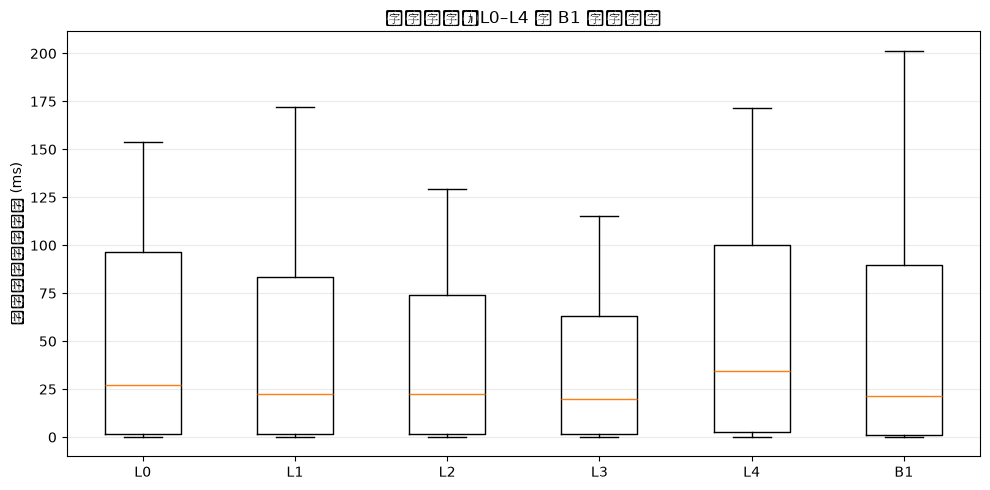

C:\Users\AngelXY\AppData\Local\Temp\ipykernel_34908\4285061909.py:102: UserWarning: Glyph 30456 (\N{CJK UNIFIED IDEOGRAPH-76F8}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\AngelXY\AppData\Local\Temp\ipykernel_34908\4285061909.py:102: UserWarning: Glyph 23545 (\N{CJK UNIFIED IDEOGRAPH-5BF9}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\AngelXY\AppData\Local\Temp\ipykernel_34908\4285061909.py:102: UserWarning: Glyph 29031 (\N{CJK UNIFIED IDEOGRAPH-7167}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\AngelXY\AppData\Local\Temp\ipykernel_34908\4285061909.py:102: UserWarning: Glyph 29256 (\N{CJK UNIFIED IDEOGRAPH-7248}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\AngelXY\AppData\Local\Temp\ipykernel_34908\4285061909.py:102: UserWarning: Glyph 26412 (\N{CJK UNIFIED IDEOGRAPH-672C}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\AngelXY\AppData\Local\Temp\ipykernel_34908\4285061909.py:102: UserWarni

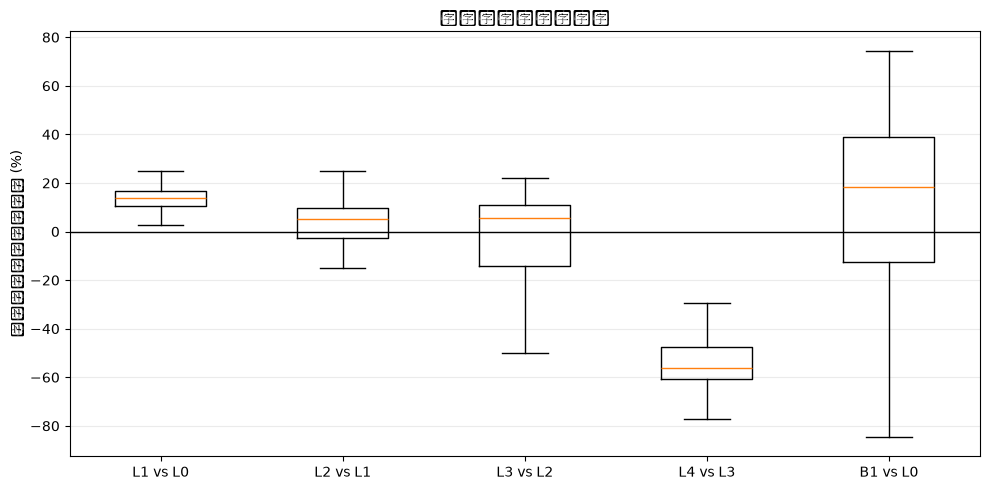

C:\Users\AngelXY\AppData\Local\Temp\ipykernel_34908\4285061909.py:121: UserWarning: Glyph 33410 (\N{CJK UNIFIED IDEOGRAPH-8282}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\AngelXY\AppData\Local\Temp\ipykernel_34908\4285061909.py:121: UserWarning: Glyph 28857 (\N{CJK UNIFIED IDEOGRAPH-70B9}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\AngelXY\AppData\Local\Temp\ipykernel_34908\4285061909.py:121: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\AngelXY\AppData\Local\Temp\ipykernel_34908\4285061909.py:121: UserWarning: Glyph 27599 (\N{CJK UNIFIED IDEOGRAPH-6BCF}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\AngelXY\AppData\Local\Temp\ipykernel_34908\4285061909.py:121: UserWarning: Glyph 32452 (\N{CJK UNIFIED IDEOGRAPH-7EC4}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\AngelXY\AppData\Local\Temp\ipykernel_34908\4285061909.py:121: UserWarni

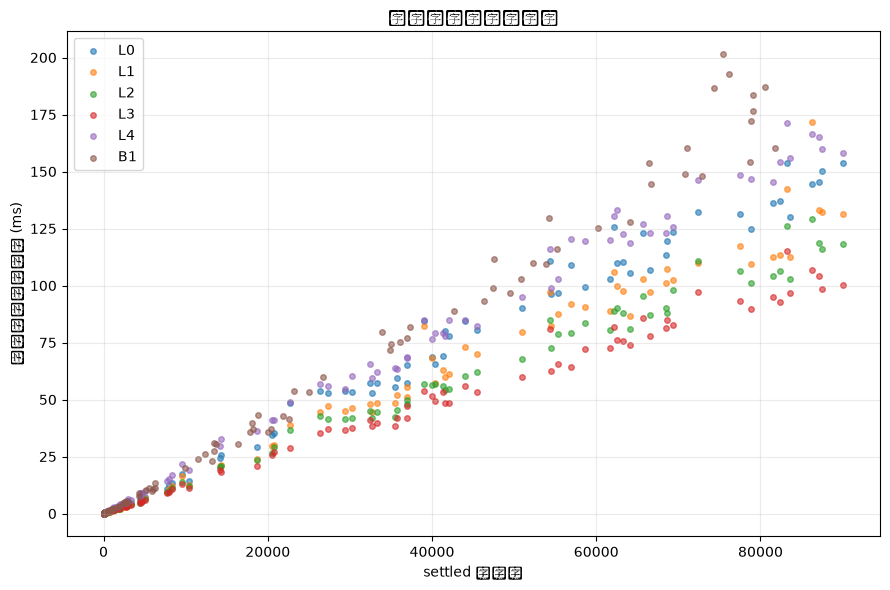

结果已导出到：d:\pycharm\projects\route_plan\workspaces\A3_性能\03_实验结果\武汉\Dijkstra\run_20261018_093632_854247


In [9]:
# Cell 6：配对统计、图表与结果导出

# 先对每个“版本 × 查询”的多轮耗时取中位数，再做配对汇总。
query_medians = (
    raw_df.groupby(["layer", "query_id"], as_index=False)
    .agg(
        query_median_ms=("elapsed_ms", "median"),
        settled_nodes=("settled_nodes", "median"),
    )
)

summary = (
    query_medians.groupby("layer", sort=False)
    .agg(
        median_ms=("query_median_ms", "median"),
        q1_ms=("query_median_ms", lambda x: x.quantile(0.25)),
        q3_ms=("query_median_ms", lambda x: x.quantile(0.75)),
        mean_settled_nodes=("settled_nodes", "mean"),
    )
    .reindex(ALGORITHM_ORDER)
)

latency_by_query = query_medians.pivot(
    index="query_id", columns="layer", values="query_median_ms"
)

comparisons = [
    ("L1", "L0"),
    ("L2", "L1"),
    ("L3", "L2"),
    ("L4", "L3"),
    ("B1", "L0"),
]

paired_rows = []
paired_values = {}

for layer, previous in comparisons:
    # 正值表示当前版本比对照版本快。
    change_pct = (
        (latency_by_query[previous] - latency_by_query[layer])
        / latency_by_query[previous]
        * 100
    )
    label = f"{layer} vs {previous}"
    paired_values[label] = change_pct

    paired_rows.append({
        "comparison": label,
        "median_change_pct": change_pct.median(),
        "q1_change_pct": change_pct.quantile(0.25),
        "q3_change_pct": change_pct.quantile(0.75),
    })

paired_summary = pd.DataFrame(paired_rows)

# L1 全图预检成本的查询量摊销估算；查询耗时使用固定查询集的中位数。
batch_sizes = (1, 10, 50, 100, 500, 1000)
l0_query_ms = latency_by_query["L0"].median()
l1_query_ms = latency_by_query["L1"].median()

amortization = pd.DataFrame([
    {
        "query_batch": count,
        "L0_total_ms_est": count * l0_query_ms,
        "L1_total_ms_est": l1_precheck_ms + count * l1_query_ms,
        "L0_ms_per_query_est": l0_query_ms,
        "L1_ms_per_query_est": (l1_precheck_ms + count * l1_query_ms) / count,
    }
    for count in batch_sizes
])

display(summary.round(3))
display(paired_summary.round(3))
display(amortization.round(3))

# 查询耗时分布
fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(
    [query_medians.loc[query_medians["layer"] == layer, "query_median_ms"]
     for layer in ALGORITHM_ORDER],
    tick_labels=ALGORITHM_ORDER,
    showfliers=False,
)
ax.set_ylabel("每组查询中位耗时 (ms)")
ax.set_title("武汉路网：L0–L4 与 B1 查询耗时")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

# 配对查询的相对变化，正值表示提速
fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot(
    list(paired_values.values()),
    tick_labels=list(paired_values.keys()),
    showfliers=False,
)
ax.axhline(0, color="black", linewidth=1)
ax.set_ylabel("相对对照版本耗时变化 (%)")
ax.set_title("逐查询配对耗时变化")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

# 搜索规模与耗时关系
fig, ax = plt.subplots(figsize=(9, 6))
for layer in ALGORITHM_ORDER:
    rows = query_medians[query_medians["layer"] == layer]
    ax.scatter(
        rows["settled_nodes"],
        rows["query_median_ms"],
        s=16,
        alpha=0.6,
        label=layer,
    )
ax.set_xlabel("settled 节点数")
ax.set_ylabel("每组查询中位耗时 (ms)")
ax.set_title("搜索规模与查询耗时")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

# 只有运行本 cell 时才会创建结果目录并导出实验结果。
RESULT_DIR.mkdir(parents=True, exist_ok=True)

raw_df.to_csv(RESULT_DIR / "dijkstra_raw.csv", index=False, encoding="utf-8-sig")
query_medians.to_csv(
    RESULT_DIR / "dijkstra_query_medians.csv", index=False, encoding="utf-8-sig"
)
summary.to_csv(RESULT_DIR / "dijkstra_summary.csv", encoding="utf-8-sig")
paired_summary.to_csv(
    RESULT_DIR / "dijkstra_paired_changes.csv", index=False, encoding="utf-8-sig"
)
amortization.to_csv(
    RESULT_DIR / "dijkstra_l1_amortization.csv", index=False, encoding="utf-8-sig"
)

metadata = {
    "environment": ENVIRONMENT,
    "dataset": {
        "file": str(GRAPH_FILE),
        "sha256": GRAPH_SHA256,
        "nodes": N_NODES,
        "directed_edges": N_EDGES,
        "graph_policy": EXPECTED_GRAPH_POLICY,
        "load_ms": graph_load_ms,
        "adjacency_conversion_ms": adjacency_conversion_ms,
        "l1_precheck_ms": l1_precheck_ms,
        "b1_reverse_graph_build_ms": reverse_graph_build_ms,
    },
    "queries": {
        "file": str(QUERY_FILE),
        "sha256": QUERY_SHA256,
        "count": len(queries),
        "seed": query_data["seed"],
    },
    "benchmark": {
        "rounds": ROUNDS,
        "warmup_queries_per_layer": WARMUP_QUERY_COUNT,
        "order_seed": ORDER_SEED,
        "timing": "perf_counter_ns; per-query randomized version order",
        "layers": list(ALGORITHM_ORDER),
        "correctness_passed": True,
        "reported_search_count": "settled_nodes returned by each implementation",
    },
}

with (RESULT_DIR / "dijkstra_metadata.json").open("w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

print(f"结果已导出到：{RESULT_DIR}")

In [10]:
# C++-1：加载 DLL 并声明接口

import ctypes as CPP_CT
from pathlib import Path as CPP_Path

CPP_DLL_PATH = CODE_DIR / ".build" / "dijkstra_cpp.dll"

if CPP_CT.sizeof(CPP_CT.c_void_p) != 8:
    raise RuntimeError("当前 DLL 是 64 位版本，需要使用 64 位 Python 内核。")

if not CPP_DLL_PATH.is_file():
    raise FileNotFoundError(f"找不到 C++ DLL：{CPP_DLL_PATH}")

try:
    CPP_LIB = CPP_CT.CDLL(str(CPP_DLL_PATH))
except OSError as exc:
    raise RuntimeError(
        f"DLL 加载失败：{CPP_DLL_PATH}\n"
        "请确认 DLL 与当前 Python 的位数一致，且所需的 MSVC 运行库可用。"
    ) from exc


CPP_I64_P = CPP_CT.POINTER(CPP_CT.c_int64)
CPP_DOUBLE_P = CPP_CT.POINTER(CPP_CT.c_double)
CPP_U64_P = CPP_CT.POINTER(CPP_CT.c_uint64)


# 算法编号与 dijkstra_cpp.cpp 中的定义一致
CPP_ALGORITHM_IDS = {
    "L0": 0,
    "L1": 1,
    "L2": 2,
    "L3": 3,
    "L4": 4,
    "B1": 5,
}

# dijkstra_run 的返回状态码
CPP_STATUS_NAMES = {
    0: "OK",
    1: "INVALID_ARGUMENT",
    2: "INVALID_GRAPH",
    3: "INVALID_QUERY",
    4: "BUFFER_TOO_SMALL",
    5: "INTERNAL_ERROR",
}


# 创建 C++ 图对象
CPP_LIB.dijkstra_graph_create.argtypes = [
    CPP_CT.c_int64,   # n_nodes
    CPP_CT.c_int64,   # n_edges
    CPP_I64_P,        # indptr
    CPP_I64_P,        # indices
    CPP_DOUBLE_P,     # weights
    CPP_I64_P,        # edge_ids
    CPP_CT.POINTER(CPP_CT.c_int32),  # error_code
]
CPP_LIB.dijkstra_graph_create.restype = CPP_CT.c_void_p


# 释放 C++ 图对象
CPP_LIB.dijkstra_graph_destroy.argtypes = [CPP_CT.c_void_p]
CPP_LIB.dijkstra_graph_destroy.restype = None


# 执行一次 C++ 路径查询
CPP_LIB.dijkstra_run.argtypes = [
    CPP_CT.c_void_p,  # graph handle
    CPP_CT.c_int32,   # algorithm
    CPP_CT.c_int64,   # start
    CPP_CT.c_int64,   # goal
    CPP_I64_P,        # node_buffer
    CPP_CT.c_int64,   # node_capacity
    CPP_I64_P,        # edge_buffer
    CPP_CT.c_int64,   # edge_capacity
    CPP_CT.POINTER(CPP_CT.c_int64),  # node_count
    CPP_CT.POINTER(CPP_CT.c_int64),  # edge_count
    CPP_DOUBLE_P,     # total_distance
    CPP_U64_P,        # settled_count
    CPP_U64_P,        # elapsed_ns
]
CPP_LIB.dijkstra_run.restype = CPP_CT.c_int32


print(f"C++ DLL loaded: {CPP_DLL_PATH}")
print("Algorithms:", ", ".join(CPP_ALGORITHM_IDS))

C++ DLL loaded: d:\pycharm\projects\route_plan\workspaces\A3_性能\01_基准方法\代码\.build\dijkstra_cpp.dll
Algorithms: L0, L1, L2, L3, L4, B1


In [11]:
# C++-2：准备 CSR 数据并创建 C++ 图对象

import numpy as CPP_NP
import time as CPP_TIME


# 如果重复运行本 cell，先释放上一次创建的 C++ 图对象。
if globals().get("CPP_GRAPH_HANDLE"):
    CPP_LIB.dijkstra_graph_destroy(CPP_GRAPH_HANDLE)
    CPP_GRAPH_HANDLE = None


# ctypes 接口要求连续的 int64 / float64 数组。
CPP_ARRAY_START_NS = CPP_TIME.perf_counter_ns()

CPP_INDPTR = CPP_NP.ascontiguousarray(CSR_GRAPH["indptr"], dtype=CPP_NP.int64)
CPP_INDICES = CPP_NP.ascontiguousarray(CSR_GRAPH["indices"], dtype=CPP_NP.int64)
CPP_WEIGHTS = CPP_NP.ascontiguousarray(CSR_GRAPH["weights"], dtype=CPP_NP.float64)
CPP_EDGE_IDS = CPP_NP.ascontiguousarray(CSR_GRAPH["edge_ids"], dtype=CPP_NP.int64)

CPP_ARRAY_PREP_MS = (
    CPP_TIME.perf_counter_ns() - CPP_ARRAY_START_NS
) / 1e6


# 先检查数组长度，避免把不匹配的缓冲区传入 C++。
if CPP_INDPTR.ndim != 1 or len(CPP_INDPTR) != N_NODES + 1:
    raise ValueError("C++ 输入的 indptr 长度应为 N_NODES + 1")

if not (
    CPP_INDICES.ndim == CPP_WEIGHTS.ndim == CPP_EDGE_IDS.ndim == 1
    and len(CPP_INDICES) == len(CPP_WEIGHTS) == len(CPP_EDGE_IDS) == N_EDGES
):
    raise ValueError("C++ 输入的 indices、weights、edge_ids 长度不一致")

if int(CPP_INDPTR[0]) != 0 or int(CPP_INDPTR[-1]) != N_EDGES:
    raise ValueError("C++ 输入的 indptr 首尾值与边数不一致")


CPP_GRAPH_ERROR = CPP_CT.c_int32()
CPP_GRAPH_START_NS = CPP_TIME.perf_counter_ns()

CPP_GRAPH_HANDLE = CPP_LIB.dijkstra_graph_create(
    int(N_NODES),
    int(N_EDGES),
    CPP_INDPTR.ctypes.data_as(CPP_I64_P),
    CPP_INDICES.ctypes.data_as(CPP_I64_P),
    CPP_WEIGHTS.ctypes.data_as(CPP_DOUBLE_P),
    CPP_EDGE_IDS.ctypes.data_as(CPP_I64_P),
    CPP_CT.byref(CPP_GRAPH_ERROR),
)

CPP_GRAPH_CREATE_MS = (
    CPP_TIME.perf_counter_ns() - CPP_GRAPH_START_NS
) / 1e6


if not CPP_GRAPH_HANDLE or CPP_GRAPH_ERROR.value != 0:
    if CPP_GRAPH_HANDLE:
        CPP_LIB.dijkstra_graph_destroy(CPP_GRAPH_HANDLE)
        CPP_GRAPH_HANDLE = None

    status_name = CPP_STATUS_NAMES.get(
        CPP_GRAPH_ERROR.value,
        f"UNKNOWN_STATUS_{CPP_GRAPH_ERROR.value}",
    )
    raise RuntimeError(f"C++ 建图失败：{status_name}")


print(f"C++ graph ready: {N_NODES:,} nodes, {N_EDGES:,} directed edges")
print(f"NumPy array preparation: {CPP_ARRAY_PREP_MS:.3f} ms")
print(f"C++ graph creation: {CPP_GRAPH_CREATE_MS:.3f} ms")

C++ graph ready: 91,638 nodes, 207,165 directed edges
NumPy array preparation: 1.757 ms
C++ graph creation: 38.255 ms


In [12]:
# C++-3：查询适配函数与接口冒烟测试

import numpy as CPP_NP
# 复用缓冲区，避免每次查询都分配与整张图同规模的数组。
CPP_NODE_BUFFER = CPP_NP.empty(N_NODES, dtype=CPP_NP.int64)
CPP_EDGE_BUFFER = CPP_NP.empty(N_NODES, dtype=CPP_NP.int64)


def run_cpp_algorithm(layer, source, target):
    """返回 (节点路径, edge_id 路径, 距离, settled 数, C++ 内部耗时_ns)。"""
    if layer not in CPP_ALGORITHM_IDS:
        raise ValueError(f"未知的 C++ 算法版本：{layer}")

    source = int(source)
    target = int(target)
    if not (0 <= source < N_NODES and 0 <= target < N_NODES):
        raise ValueError(f"起点或终点越界：{source} -> {target}")

    node_count = CPP_CT.c_int64()
    edge_count = CPP_CT.c_int64()
    distance = CPP_CT.c_double()
    settled_count = CPP_CT.c_uint64()
    elapsed_ns = CPP_CT.c_uint64()

    status = CPP_LIB.dijkstra_run(
        CPP_GRAPH_HANDLE,
        CPP_ALGORITHM_IDS[layer],
        source,
        target,
        CPP_NODE_BUFFER.ctypes.data_as(CPP_I64_P),
        int(CPP_NODE_BUFFER.size),
        CPP_EDGE_BUFFER.ctypes.data_as(CPP_I64_P),
        int(CPP_EDGE_BUFFER.size),
        CPP_CT.byref(node_count),
        CPP_CT.byref(edge_count),
        CPP_CT.byref(distance),
        CPP_CT.byref(settled_count),
        CPP_CT.byref(elapsed_ns),
    )

    if status != 0:
        status_name = CPP_STATUS_NAMES.get(status, f"UNKNOWN_STATUS_{status}")
        raise RuntimeError(
            f"C++ 查询失败：{status_name}，"
            f"algorithm={layer}, query={source}->{target}"
        )

    if not (
        0 <= node_count.value <= CPP_NODE_BUFFER.size
        and 0 <= edge_count.value <= CPP_EDGE_BUFFER.size
    ):
        raise RuntimeError("C++ 返回的路径长度超出输出缓冲区")

    node_path = CPP_NODE_BUFFER[:node_count.value].tolist()
    edge_path = CPP_EDGE_BUFFER[:edge_count.value].tolist()

    return (
        node_path,
        edge_path,
        float(distance.value),
        int(settled_count.value),
        int(elapsed_ns.value),
    )


# 用一组固定查询检查接口；计时值仅用于确认接口正常，不作为正式实验结果。
smoke_source, smoke_target = queries[0]
CPP_SMOKE_RESULT = run_cpp_algorithm("L0", smoke_source, smoke_target)
PY_SMOKE_RESULT = run_algorithm("L0", smoke_source, smoke_target)

if not valid_route(CPP_SMOKE_RESULT[:4], smoke_source, smoke_target, edge_records):
    raise AssertionError("C++ 冒烟查询返回了无效路径")

if math.isfinite(float(PY_SMOKE_RESULT[2])):
    if not math.isclose(
        CPP_SMOKE_RESULT[2],
        float(PY_SMOKE_RESULT[2]),
        rel_tol=1e-10,
        abs_tol=ABS_TOL_M,
    ):
        raise AssertionError("C++ L0 与 Python L0 的冒烟查询距离不一致")
elif not math.isinf(CPP_SMOKE_RESULT[2]):
    raise AssertionError("Python L0 不可达，但 C++ L0 返回了有限距离")

CPP_SAME_NODE_RESULT = run_cpp_algorithm("L0", smoke_source, smoke_source)
if (
    CPP_SAME_NODE_RESULT[0] != [smoke_source]
    or CPP_SAME_NODE_RESULT[1] != []
    or CPP_SAME_NODE_RESULT[2] != 0.0
):
    raise AssertionError("C++ 起点等于终点的边界测试失败")

print(
    f"C++ interface smoke test passed: "
    f"{smoke_source} -> {smoke_target}, "
    f"distance={CPP_SMOKE_RESULT[2]:.3f} m"
)

C++ interface smoke test passed: 17837 -> 74913, distance=24830.228 m


In [13]:
# C++-4：固定查询集正确性核验

CPP_CORRECTNESS_RECORDS = []

for query_id, (source, target) in enumerate(queries):
    reference = run_algorithm("L0", source, target)
    reference_distance = float(reference[2])

    for layer in CPP_ALGORITHM_IDS:
        result = run_cpp_algorithm(layer, source, target)
        result_distance = float(result[2])

        if math.isfinite(reference_distance):
            same_distance = (
                math.isfinite(result_distance)
                and math.isclose(
                    result_distance,
                    reference_distance,
                    rel_tol=1e-10,
                    abs_tol=ABS_TOL_M,
                )
            )
        else:
            same_distance = math.isinf(result_distance)

        path_is_valid = valid_route(
            result[:4], source, target, edge_records
        )

        if not same_distance or not path_is_valid:
            raise AssertionError(
                f"{layer} 正确性失败：query={query_id}, "
                f"{source}->{target}, "
                f"Python L0 distance={reference_distance}, "
                f"C++ distance={result_distance}, "
                f"path_valid={path_is_valid}"
            )

        CPP_CORRECTNESS_RECORDS.append({
            "layer": layer,
            "query_id": query_id,
            "source": source,
            "target": target,
            "distance_m": result_distance,
            "settled_nodes": result[3],
            "path_valid": path_is_valid,
        })


CPP_CORRECTNESS_DF = pd.DataFrame(CPP_CORRECTNESS_RECORDS)

print(
    f"C++ 正确性通过：{len(queries)} 组查询 × "
    f"{len(CPP_ALGORITHM_IDS)} 个版本"
)
display(
    CPP_CORRECTNESS_DF.groupby("layer", sort=False).agg(
        queries=("query_id", "count"),
        mean_settled_nodes=("settled_nodes", "mean"),
        all_paths_valid=("path_valid", "all"),
    )
)

C++ 正确性通过：100 组查询 × 6 个版本


,queries,mean_settled_nodes,all_paths_valid
layer,,,
L0,100,28055.53,True
L1,100,28055.53,True
L2,100,28055.53,True
L3,100,28055.53,True
L4,100,28055.53,True
B1,100,23031.08,True


In [14]:
# C++-5：预热与逐查询配对计时

import random as CPP_RANDOM
import time as CPP_TIME


CPP_LAYER_ORDER = tuple(CPP_ALGORITHM_IDS)
CPP_WARMUP_QUERIES = queries[:WARMUP_QUERY_COUNT]

if not CPP_WARMUP_QUERIES:
    raise ValueError("预热查询集为空")


# 预热不进入正式计时记录。
for layer in CPP_LAYER_ORDER:
    for source, target in CPP_WARMUP_QUERIES:
        run_cpp_algorithm(layer, source, target)


CPP_RNG = CPP_RANDOM.Random(ORDER_SEED)
CPP_RAW_RECORDS = []

for round_id in range(1, ROUNDS + 1):
    for query_id, (source, target) in enumerate(queries):
        layer_order = list(CPP_LAYER_ORDER)
        CPP_RNG.shuffle(layer_order)

        for layer in layer_order:
            outer_start_ns = CPP_TIME.perf_counter_ns()
            result = run_cpp_algorithm(layer, source, target)
            elapsed_outer_ns = CPP_TIME.perf_counter_ns() - outer_start_ns

            CPP_RAW_RECORDS.append({
                "layer": layer,
                "round": round_id,
                "query_id": query_id,
                "source": source,
                "target": target,
                "elapsed_outer_ns": elapsed_outer_ns,
                "elapsed_kernel_ns": result[4],
                "distance_m": float(result[2]),
                "settled_nodes": int(result[3]),
            })


CPP_RAW_DF = pd.DataFrame(CPP_RAW_RECORDS)
expected_runs = ROUNDS * len(queries) * len(CPP_LAYER_ORDER)

if len(CPP_RAW_DF) != expected_runs:
    raise AssertionError(
        f"计时记录数不符：expected={expected_runs}, "
        f"actual={len(CPP_RAW_DF)}"
    )

print(
    f"C++ 计时完成：{ROUNDS} 轮 × {len(queries)} 组查询 "
    f"× {len(CPP_LAYER_ORDER)} 个版本，共 {len(CPP_RAW_DF):,} 次查询"
)
display(CPP_RAW_DF.head())

C++ 计时完成：5 轮 × 100 组查询 × 6 个版本，共 3,000 次查询


,layer,round,query_id,source,target,elapsed_outer_ns,elapsed_kernel_ns,distance_m,settled_nodes
0,L0,1,0,17837,74913,52490300,52397400,24830.227922,39999
1,B1,1,0,17837,74913,27110200,27001700,24830.227922,26720
2,L2,1,0,17837,74913,17749900,17640300,24830.227922,39999
3,L3,1,0,17837,74913,6747900,6656900,24830.227922,39999
4,L4,1,0,17837,74913,5388600,5304800,24830.227922,39999


,outer_median_ms,outer_q1_ms,outer_q3_ms,kernel_median_ms,kernel_q1_ms,kernel_q3_ms,mean_settled_nodes
layer,,,,,,,
L0,10.231,0.603,44.505,10.166,0.581,44.404,28055.53
L1,10.516,0.600,45.856,10.432,0.577,45.748,28055.53
L2,5.608,0.382,21.162,5.522,0.367,21.052,28055.53
L3,2.519,0.288,7.857,2.476,0.257,7.758,28055.53
L4,2.204,0.284,6.622,2.133,0.258,6.520,28055.53
B1,7.400,0.317,42.340,7.312,0.291,42.235,23031.08


,timing,comparison,paired_queries,median_change_pct,q1_change_pct,q3_change_pct
0,outer,L1 vs L0,100,-0.635,-4.023,5.524
1,outer,L2 vs L1,100,45.505,30.958,53.096
2,outer,L3 vs L2,100,55.238,28.664,64.933
3,outer,L4 vs L3,100,11.056,4.480,15.959
4,outer,B1 vs L0,100,30.894,-6.118,45.834
5,kernel,L1 vs L0,100,-0.626,-4.274,5.531
6,kernel,L2 vs L1,100,45.763,30.893,53.281
7,kernel,L3 vs L2,100,56.142,30.900,65.310
8,kernel,L4 vs L3,100,10.818,2.972,16.189
9,kernel,B1 vs L0,100,30.969,-6.683,47.245


C:\Users\AngelXY\AppData\Local\Temp\ipykernel_34908\3030888660.py:114: UserWarning: Glyph 27599 (\N{CJK UNIFIED IDEOGRAPH-6BCF}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\AngelXY\AppData\Local\Temp\ipykernel_34908\3030888660.py:114: UserWarning: Glyph 32452 (\N{CJK UNIFIED IDEOGRAPH-7EC4}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\AngelXY\AppData\Local\Temp\ipykernel_34908\3030888660.py:114: UserWarning: Glyph 26597 (\N{CJK UNIFIED IDEOGRAPH-67E5}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\AngelXY\AppData\Local\Temp\ipykernel_34908\3030888660.py:114: UserWarning: Glyph 35810 (\N{CJK UNIFIED IDEOGRAPH-8BE2}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\AngelXY\AppData\Local\Temp\ipykernel_34908\3030888660.py:114: UserWarning: Glyph 20013 (\N{CJK UNIFIED IDEOGRAPH-4E2D}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\AngelXY\AppData\Local\Temp\ipykernel_34908\3030888660.py:114: UserWarni

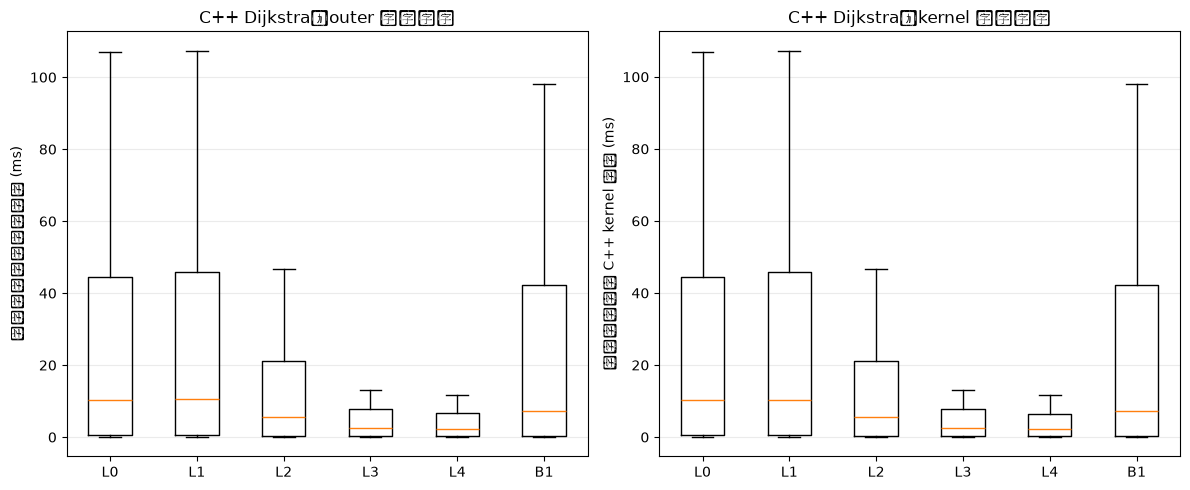

C:\Users\AngelXY\AppData\Local\Temp\ipykernel_34908\3030888660.py:141: UserWarning: Glyph 30456 (\N{CJK UNIFIED IDEOGRAPH-76F8}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\AngelXY\AppData\Local\Temp\ipykernel_34908\3030888660.py:141: UserWarning: Glyph 23545 (\N{CJK UNIFIED IDEOGRAPH-5BF9}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\AngelXY\AppData\Local\Temp\ipykernel_34908\3030888660.py:141: UserWarning: Glyph 29031 (\N{CJK UNIFIED IDEOGRAPH-7167}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\AngelXY\AppData\Local\Temp\ipykernel_34908\3030888660.py:141: UserWarning: Glyph 29256 (\N{CJK UNIFIED IDEOGRAPH-7248}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\AngelXY\AppData\Local\Temp\ipykernel_34908\3030888660.py:141: UserWarning: Glyph 26412 (\N{CJK UNIFIED IDEOGRAPH-672C}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\AngelXY\AppData\Local\Temp\ipykernel_34908\3030888660.py:141: UserWarni

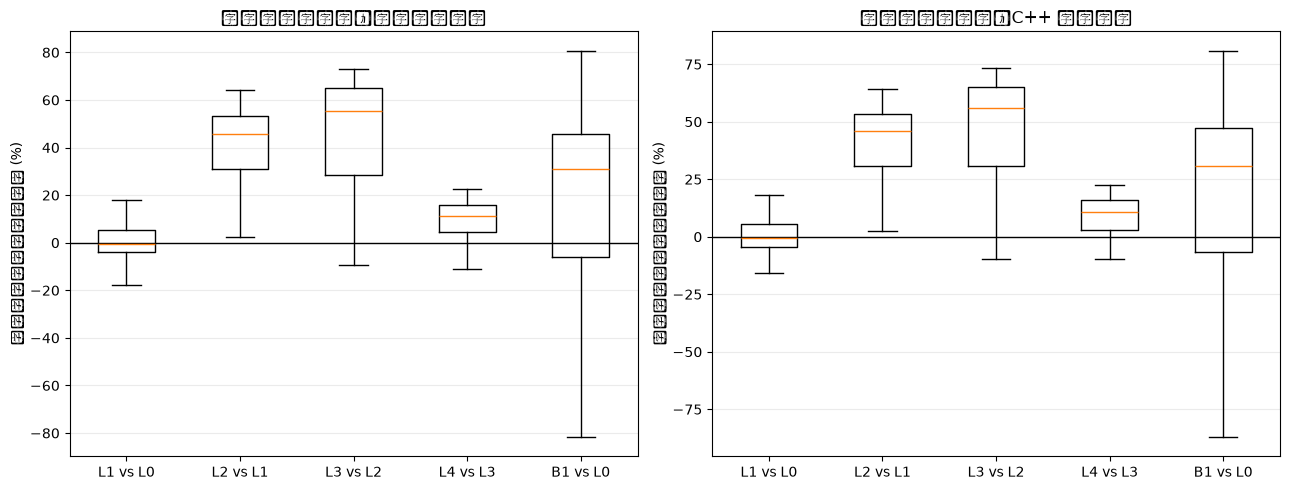

C:\Users\AngelXY\AppData\Local\Temp\ipykernel_34908\3030888660.py:168: UserWarning: Glyph 33410 (\N{CJK UNIFIED IDEOGRAPH-8282}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\AngelXY\AppData\Local\Temp\ipykernel_34908\3030888660.py:168: UserWarning: Glyph 28857 (\N{CJK UNIFIED IDEOGRAPH-70B9}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\AngelXY\AppData\Local\Temp\ipykernel_34908\3030888660.py:168: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\AngelXY\AppData\Local\Temp\ipykernel_34908\3030888660.py:168: UserWarning: Glyph 27599 (\N{CJK UNIFIED IDEOGRAPH-6BCF}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\AngelXY\AppData\Local\Temp\ipykernel_34908\3030888660.py:168: UserWarning: Glyph 32452 (\N{CJK UNIFIED IDEOGRAPH-7EC4}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
C:\Users\AngelXY\AppData\Local\Temp\ipykernel_34908\3030888660.py:168: UserWarni

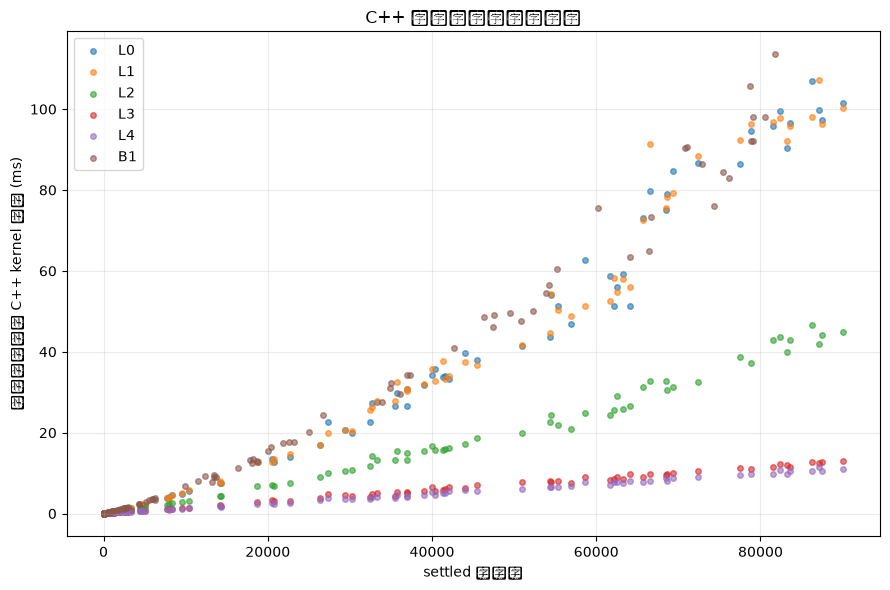

C++ 结果和图表已导出到：d:\pycharm\projects\route_plan\workspaces\A3_性能\03_实验结果\武汉\Dijkstra\run_20261018_093632_854247\cpp_dijkstra


In [15]:
# C++-6：汇总、配对比较与结果导出


CPP_RAW_DF["elapsed_outer_ms"] = CPP_RAW_DF["elapsed_outer_ns"] / 1e6
CPP_RAW_DF["elapsed_kernel_ms"] = CPP_RAW_DF["elapsed_kernel_ns"] / 1e6


# 先汇总每个“算法版本 × 查询”的多轮中位耗时。
CPP_QUERY_MEDIANS = (
    CPP_RAW_DF.groupby(["layer", "query_id"], as_index=False)
    .agg(
        outer_query_median_ms=("elapsed_outer_ms", "median"),
        kernel_query_median_ms=("elapsed_kernel_ms", "median"),
        settled_nodes=("settled_nodes", "median"),
    )
)


# 再汇总每个版本的查询耗时分布和平均搜索规模。
CPP_SUMMARY = (
    CPP_QUERY_MEDIANS.groupby("layer", sort=False)
    .agg(
        outer_median_ms=("outer_query_median_ms", "median"),
        outer_q1_ms=("outer_query_median_ms", lambda x: x.quantile(0.25)),
        outer_q3_ms=("outer_query_median_ms", lambda x: x.quantile(0.75)),
        kernel_median_ms=("kernel_query_median_ms", "median"),
        kernel_q1_ms=("kernel_query_median_ms", lambda x: x.quantile(0.25)),
        kernel_q3_ms=("kernel_query_median_ms", lambda x: x.quantile(0.75)),
        mean_settled_nodes=("settled_nodes", "mean"),
    )
    .reindex(CPP_LAYER_ORDER)
)


# 正值表示当前版本比对照版本快。
CPP_COMPARISONS = [
    ("L1", "L0"),
    ("L2", "L1"),
    ("L3", "L2"),
    ("L4", "L3"),
    ("B1", "L0"),
]

CPP_PAIRED_ROWS = []
CPP_PAIRED_DISTRIBUTIONS = {}

for metric, value_column in (
    ("outer", "outer_query_median_ms"),
    ("kernel", "kernel_query_median_ms"),
):
    latency_by_query = CPP_QUERY_MEDIANS.pivot(
        index="query_id",
        columns="layer",
        values=value_column,
    )
    CPP_PAIRED_DISTRIBUTIONS[metric] = {}

    for layer, previous in CPP_COMPARISONS:
        previous_values = latency_by_query[previous]
        current_values = latency_by_query[layer]
        valid_pairs = previous_values > 0

        change_pct = (
            (previous_values[valid_pairs] - current_values[valid_pairs])
            / previous_values[valid_pairs]
            * 100
        )
        label = f"{layer} vs {previous}"
        CPP_PAIRED_DISTRIBUTIONS[metric][label] = change_pct

        CPP_PAIRED_ROWS.append({
            "timing": metric,
            "comparison": label,
            "paired_queries": int(change_pct.count()),
            "median_change_pct": float(change_pct.median()),
            "q1_change_pct": float(change_pct.quantile(0.25)),
            "q3_change_pct": float(change_pct.quantile(0.75)),
        })

CPP_PAIRED_SUMMARY = pd.DataFrame(CPP_PAIRED_ROWS)

display(CPP_SUMMARY.round(3))
display(CPP_PAIRED_SUMMARY.round(3))


# 查询耗时分布：分别展示 Python 外层墙钟时间和 C++ 内部时间。
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, metric, column, ylabel in (
    (
        axes[0],
        "outer",
        "outer_query_median_ms",
        "每组查询中位墙钟时间 (ms)",
    ),
    (
        axes[1],
        "kernel",
        "kernel_query_median_ms",
        "每组查询中位 C++ kernel 时间 (ms)",
    ),
):
    values = [
        CPP_QUERY_MEDIANS.loc[
            CPP_QUERY_MEDIANS["layer"] == layer, column
        ]
        for layer in CPP_LAYER_ORDER
    ]
    ax.boxplot(values, tick_labels=CPP_LAYER_ORDER, showfliers=False)
    ax.set_ylabel(ylabel)
    ax.set_title(f"C++ Dijkstra：{metric} 查询耗时")
    ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig(
    RESULT_DIR / "cpp_dijkstra_latency.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()


# 逐查询配对耗时变化，正值代表提速。
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, metric, title in (
    (axes[0], "outer", "外层墙钟时间"),
    (axes[1], "kernel", "C++ 内部时间"),
):
    labels = list(CPP_PAIRED_DISTRIBUTIONS[metric])
    values = [
        CPP_PAIRED_DISTRIBUTIONS[metric][label]
        for label in labels
    ]
    ax.boxplot(values, tick_labels=labels, showfliers=False)
    ax.axhline(0, color="black", linewidth=1)
    ax.set_ylabel("相对对照版本的耗时变化 (%)")
    ax.set_title(f"逐查询配对变化：{title}")
    ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig(
    RESULT_DIR / "cpp_dijkstra_paired_changes.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()


# 搜索规模与 C++ 内部查询耗时的关系。
fig, ax = plt.subplots(figsize=(9, 6))

for layer in CPP_LAYER_ORDER:
    rows = CPP_QUERY_MEDIANS[CPP_QUERY_MEDIANS["layer"] == layer]
    ax.scatter(
        rows["settled_nodes"],
        rows["kernel_query_median_ms"],
        s=16,
        alpha=0.6,
        label=layer,
    )

ax.set_xlabel("settled 节点数")
ax.set_ylabel("每组查询中位 C++ kernel 时间 (ms)")
ax.set_title("C++ 搜索规模与查询耗时")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(
    RESULT_DIR / "cpp_dijkstra_search_scale.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()


# 所有 C++ 结果单独导出，不覆盖 Python 实验结果。
CPP_RESULT_DIR = RESULT_DIR / "cpp_dijkstra"
CPP_RESULT_DIR.mkdir(parents=True, exist_ok=True)

CPP_RAW_DF.to_csv(
    CPP_RESULT_DIR / "cpp_dijkstra_raw.csv",
    index=False,
    encoding="utf-8-sig",
)
CPP_QUERY_MEDIANS.to_csv(
    CPP_RESULT_DIR / "cpp_dijkstra_query_medians.csv",
    index=False,
    encoding="utf-8-sig",
)
CPP_SUMMARY.to_csv(
    CPP_RESULT_DIR / "cpp_dijkstra_summary.csv",
    encoding="utf-8-sig",
)
CPP_PAIRED_SUMMARY.to_csv(
    CPP_RESULT_DIR / "cpp_dijkstra_paired_changes.csv",
    index=False,
    encoding="utf-8-sig",
)

CPP_SOURCE_PATH = CODE_DIR / "dijkstra_cpp.cpp"
metadata = {
    "environment": ENVIRONMENT,
    "implementation": {
        "language": "C++17",
        "compiler": "MSVC x64",
        "source_file": str(CPP_SOURCE_PATH),
        "source_sha256": hashlib.sha256(
            CPP_SOURCE_PATH.read_bytes()
        ).hexdigest(),
        "dll_file": str(CPP_DLL_PATH),
        "dll_sha256": hashlib.sha256(
            CPP_DLL_PATH.read_bytes()
        ).hexdigest(),
        "layers": list(CPP_LAYER_ORDER),
    },
    "dataset": {
        "file": str(GRAPH_FILE),
        "sha256": GRAPH_SHA256,
        "nodes": N_NODES,
        "directed_edges": N_EDGES,
        "graph_policy": EXPECTED_GRAPH_POLICY,
    },
    "queries": {
        "file": str(QUERY_FILE),
        "sha256": QUERY_SHA256,
        "count": len(queries),
    },
    "preprocessing": {
        "numpy_array_prep_ms": CPP_ARRAY_PREP_MS,
        "cpp_graph_create_ms": CPP_GRAPH_CREATE_MS,
        "included_in_per_query_timing": False,
    },
    "benchmark": {
        "rounds": ROUNDS,
        "warmup_queries_per_layer": WARMUP_QUERY_COUNT,
        "order_seed": ORDER_SEED,
        "timing_order": "per-query randomized version order",
        "outer_timer": (
            "Python perf_counter_ns around run_cpp_algorithm; "
            "includes ctypes call and result conversion"
        ),
        "kernel_timer": (
            "C++ steady_clock; excludes ABI validation and output-buffer copy"
        ),
        "correctness_passed": True,
        "bidirectional_settled_count": (
            "sum of forward and backward settled events"
        ),
    },
}

with (CPP_RESULT_DIR / "cpp_dijkstra_metadata.json").open(
    "w",
    encoding="utf-8",
) as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

print(f"C++ 结果和图表已导出到：{CPP_RESULT_DIR}")

In [18]:
# 统一路径信息输出（独立展示，不计入前面的基准；不会覆盖历史结果）
import importlib.util
import json
import time

_output_spec = importlib.util.spec_from_file_location(
    "a3_route_output_display", VARIANTS_FILE.parent / "route_output.py")
_output_module = importlib.util.module_from_spec(_output_spec)
_output_spec.loader.exec_module(_output_module)
_planner_spec = importlib.util.spec_from_file_location(
    "a3_route_planner_speed_source", VARIANTS_FILE.parent / "route_planner.py")
_planner_module = importlib.util.module_from_spec(_planner_spec)
_planner_spec.loader.exec_module(_planner_module)
_edge_speed_overrides = _planner_module._load_osm_maxspeed_overrides(
    GRAPH_FILE.with_name("wuhan_distance_v2.graphml"), edge_records)
route_source, route_target = queries[0]
_route_started = time.perf_counter()
_route_raw = run_algorithm("L4", route_source, route_target)
_route_planning_ms = (time.perf_counter() - _route_started) * 1000
route_output = _output_module.build_route_output(
    _route_raw, edge_records, route_source, route_target,
    algorithm="dijkstra-L4", planning_ms=_route_planning_ms,
    edge_speed_overrides=_edge_speed_overrides,
    assumed_speed_kmh=None,  # OSM maxspeed 按平均速度；等级回退值标为估算
)
print(json.dumps(route_output, ensure_ascii=False, indent=2, allow_nan=False))


{
  "schema_version": "a3.route.v1",
  "status": "ok",
  "algorithm": "dijkstra-L4",
  "source": 17837,
  "target": 74913,
  "node_ids": [
    17837,
    17838,
    77085,
    77049,
    77075,
    77090,
    77089,
    39634,
    88317,
    39632,
    39627,
    11269,
    11266,
    11274,
    17884,
    17883,
    21976,
    17885,
    11919,
    63741,
    80553,
    11918,
    28128,
    28127,
    38,
    17872,
    17870,
    17867,
    17868,
    10808,
    10793,
    10779,
    10776,
    10789,
    10796,
    76814,
    35897,
    20546,
    76817,
    10781,
    5280,
    10757,
    33069,
    10760,
    10498,
    3067,
    10531,
    72697,
    10535,
    10530,
    72712,
    10525,
    10521,
    10512,
    10511,
    10524,
    34870,
    10533,
    10548,
    4369,
    4375,
    10008,
    366,
    88289,
    88299,
    18147,
    20252,
    20314,
    12718,
    12713,
    12708,
    12701,
    81678,
    81675,
    81676,
    81674,
    85314,
    85312,
    1710,
  

In [19]:
# C++ 统一路径信息输出（复用 route_output.py；搜索计时不包含结果整理）
cpp_route_source, cpp_route_target = queries[0]
cpp_route_started = time.perf_counter()
cpp_route_result = run_cpp_algorithm("L4", cpp_route_source, cpp_route_target)
cpp_route_planning_ms = (time.perf_counter() - cpp_route_started) * 1000
cpp_route = _output_module.build_route_output(
    cpp_route_result[:4], edge_records, cpp_route_source, cpp_route_target,
    algorithm="dijkstra-cpp-L4", planning_ms=cpp_route_planning_ms,
    edge_speed_overrides=_edge_speed_overrides,
    assumed_speed_kmh=None,
)
print(json.dumps(cpp_route, ensure_ascii=False, indent=2, allow_nan=False))


{
  "schema_version": "a3.route.v1",
  "status": "ok",
  "algorithm": "dijkstra-cpp-L4",
  "source": 17837,
  "target": 74913,
  "node_ids": [
    17837,
    17838,
    77085,
    77049,
    77075,
    77090,
    77089,
    39634,
    88317,
    39632,
    39627,
    11269,
    11266,
    11274,
    17884,
    17883,
    21976,
    17885,
    11919,
    63741,
    80553,
    11918,
    28128,
    28127,
    38,
    17872,
    17870,
    17867,
    17868,
    10808,
    10793,
    10779,
    10776,
    10789,
    10796,
    76814,
    35897,
    20546,
    76817,
    10781,
    5280,
    10757,
    33069,
    10760,
    10498,
    3067,
    10531,
    72697,
    10535,
    10530,
    72712,
    10525,
    10521,
    10512,
    10511,
    10524,
    34870,
    10533,
    10548,
    4369,
    4375,
    10008,
    366,
    88289,
    88299,
    18147,
    20252,
    20314,
    12718,
    12713,
    12708,
    12701,
    81678,
    81675,
    81676,
    81674,
    85314,
    85312,
    1710